# Week 4: Building a Predictive Model
**Goal:** predict food demand (`num_orders`, on the log scale) using the feature-engineered dataset from Week 3.

**Models compared:** Ridge Regression (baseline), Random Forest, Gradient Boosting.

**Split:** time-based (train on earlier weeks, test on the last weeks) to avoid looking into the future.

## 1. Setup and load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

try:
    from lightgbm import LGBMRegressor
    GB_NAME = 'LightGBM'
    def make_gb():
        return LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=63,
                             random_state=42, n_jobs=-1, verbose=-1)
except ImportError:
    from sklearn.ensemble import HistGradientBoostingRegressor
    GB_NAME = 'HistGradientBoosting'
    def make_gb():
        return HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05,
                                             max_leaf_nodes=63, random_state=42)

print('Gradient boosting model in use:', GB_NAME)

Gradient boosting model in use: HistGradientBoosting


In [2]:
df = pd.read_csv('./Data/feature_engineered_food_demand.csv')   # change the path if needed
print(df.shape)
df.head()

(456548, 49)


,week,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,op_area,num_orders_log,discount,has_negative_discount,...,center_type_TYPE_B,center_type_TYPE_C,region_code_23,region_code_34,region_code_35,region_code_56,region_code_71,region_code_77,region_code_85,region_code_93
0,1,181.39,181.39,0,0,865,6.3,6.763885,0.0,0,...,1,0,0,0,0,1,0,0,0,0
1,2,183.36,182.36,0,0,782,6.3,6.663133,-1.0,1,...,1,0,0,0,0,1,0,0,0,0
2,3,184.36,182.36,0,0,851,6.3,6.747587,-2.0,1,...,1,0,0,0,0,1,0,0,0,0
3,4,182.36,183.36,0,0,1202,6.3,7.092574,1.0,0,...,1,0,0,0,0,1,0,0,0,0
4,5,183.39,181.39,0,0,958,6.3,6.865891,-2.0,1,...,1,0,0,0,0,1,0,0,0,0


In [3]:
# Sanity checks
print('Missing values:', df.isnull().sum().sum())
print('Non-numeric columns:', df.select_dtypes(exclude='number').columns.tolist())
print('Weeks range:', df['week'].min(), 'to', df['week'].max())

Missing values: 0
Non-numeric columns: []
Weeks range: 1 to 145


## 2. Target and features
- Target: `num_orders_log` (already in the file)
- Dropped from X: `num_orders` and `num_orders_log` (they ARE the answer, keeping them would be data leakage) and `week` (used only for the split)

In [4]:
TARGET = 'num_orders_log'
DROP_FROM_X = ['num_orders', 'num_orders_log', 'week']

y = df[TARGET]
X = df.drop(columns=[c for c in DROP_FROM_X if c in df.columns])
print('Features used:', X.shape[1])
print(X.columns.tolist())

Features used: 46
['checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'op_area', 'discount', 'has_negative_discount', 'orders_last_week_log', 'rolling_avg_3wk_log', 'discount_pct', 'price_vs_category_avg', 'discount_x_promo', 'center_avg_orders_log', 'meal_avg_orders_log', 'checkout_price_scaled', 'base_price_scaled', 'op_area_scaled', 'category_Beverages', 'category_Biryani', 'category_Desert', 'category_Extras', 'category_Fish', 'category_Other Snacks', 'category_Pasta', 'category_Pizza', 'category_Rice Bowl', 'category_Salad', 'category_Sandwich', 'category_Seafood', 'category_Soup', 'category_Starters', 'cuisine_Continental', 'cuisine_Indian', 'cuisine_Italian', 'cuisine_Thai', 'center_type_TYPE_A', 'center_type_TYPE_B', 'center_type_TYPE_C', 'region_code_23', 'region_code_34', 'region_code_35', 'region_code_56', 'region_code_71', 'region_code_77', 'region_code_85', 'region_code_93']


## 3. Time-based train/test split
The last 10 weeks are held out as the test set. A random split would let the model learn from weeks that come *after* the ones it is tested on.

In [5]:
TEST_WEEKS = 10
cutoff = df['week'].max() - TEST_WEEKS
train_mask = df['week'] <= cutoff
test_mask = ~train_mask

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f'Train: weeks {df.loc[train_mask, "week"].min()}-{cutoff}  -> {len(X_train):,} rows')
print(f'Test : weeks {cutoff + 1}-{df["week"].max()}  -> {len(X_test):,} rows')

Train: weeks 1-135  -> 423,727 rows
Test : weeks 136-145  -> 32,821 rows


## 4. Preprocessing for Ridge only
Only the continuous columns are scaled. 0/1 columns are left alone. The scaler is fitted on the training weeks only. Tree models need no scaling.

In [6]:
binary_cols = [c for c in X.columns if X[c].nunique() <= 2]
continuous_cols = [c for c in X.columns if c not in binary_cols]
print('Binary (not scaled):', len(binary_cols))
print('Continuous (scaled for Ridge):', continuous_cols)

scaler_ct = ColumnTransformer(
    [('scale', StandardScaler(), continuous_cols)],
    remainder='passthrough'
)

Binary (not scaled): 32
Continuous (scaled for Ridge): ['checkout_price', 'base_price', 'op_area', 'discount', 'orders_last_week_log', 'rolling_avg_3wk_log', 'discount_pct', 'price_vs_category_avg', 'discount_x_promo', 'center_avg_orders_log', 'meal_avg_orders_log', 'checkout_price_scaled', 'base_price_scaled', 'op_area_scaled']


## 5. Evaluation helper
All scores are on the log scale. RMSE on `log1p(num_orders)` is the same as **RMSLE**. MAE is also reported in real order counts after converting back with `expm1`.

- **MAE = (Mean Absolute Error)** is the average size of the mistakes, ignoring direction. If the actual log value is 6.76 (865 orders) and the model predicts 6.86, that's an error of 0.10. MAE averages this over all test rows. Lower is better, and it's the easiest one to explain.
- **RMSE / RMSLE = Root Mean Square Error** - RMSE squares each error, averages them, then takes the square root. Squaring means big misses are punished much more than small ones. RMSLE is the same calculation done on log values. Because your target is already log1p, the RMSE in the notebook is the RMSLE. It's the standard score for this kind of demand dataset because it measures percentage-style errors, so being off by 50 orders on a small meal counts more than being off by 50 on a huge one. Lower is better.
- **R²** = tells you how much of the up-and-down movement in demand the model explains. 1.0 is perfect, 0 means the model does no better than always guessing the average, and a negative value means it's worse than that. An R² of 0.80 means the model explains about 80% of the variation.

In [9]:
results = []
predictions = {}

def evaluate(name, model, fit_seconds=None):
    pred_log = model.predict(X_test)
    predictions[name] = pred_log
    rmse = np.sqrt(mean_squared_error(y_test, pred_log))   # = RMSLE
    mae = mean_absolute_error(y_test, pred_log)
    r2 = r2_score(y_test, pred_log)
    mae_orders = mean_absolute_error(np.expm1(y_test), np.expm1(pred_log))
    results.append({'Model': name, 'RMSE (log) = RMSLE': rmse, 'MAE (log)': mae,
                    'R2 (log)': r2, 'MAE (orders)': mae_orders})
    print(f'{name}: RMSLE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}  MAE(orders)={mae_orders:.1f}')

## 6. Model 1: Ridge Regression (baseline)

In [10]:
ridge = Pipeline([('prep', scaler_ct), ('model', Ridge(alpha=1.0))])
ridge.fit(X_train, y_train)
evaluate('Ridge', ridge)

Ridge: RMSLE=0.5251  MAE=0.4053  R2=0.7912  MAE(orders)=70.1


## 7. Model 2: Random Forest

In [11]:
rf = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=5,
                           n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate('Random Forest', rf)

Random Forest: RMSLE=0.4945  MAE=0.3799  R2=0.8148  MAE(orders)=63.7


## 8. Model 3: Gradient Boosting

In [12]:
gb = make_gb()
gb.fit(X_train, y_train)
evaluate(GB_NAME, gb)

HistGradientBoosting: RMSLE=0.4823  MAE=0.3718  R2=0.8239  MAE(orders)=62.7


## 9. Model comparison

In [13]:
results_df = pd.DataFrame(results).set_index('Model').round(4)
results_df

,RMSE (log) = RMSLE,MAE (log),R2 (log),MAE (orders)
Model,,,,
Ridge,0.5251,0.4053,0.7912,70.1374
Random Forest,0.4945,0.3799,0.8148,63.7210
HistGradientBoosting,0.4823,0.3718,0.8239,62.7337


In [14]:
best_name = results_df['RMSE (log) = RMSLE'].idxmin()
print('Best model by RMSLE:', best_name)
best_pred = predictions[best_name]

Best model by RMSLE: HistGradientBoosting


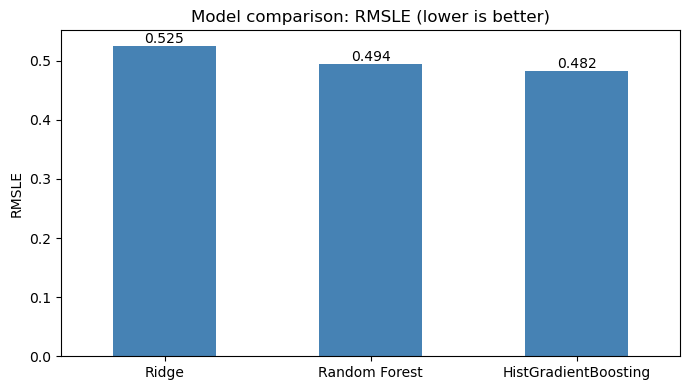

In [15]:
ax = results_df['RMSE (log) = RMSLE'].plot(kind='bar', figsize=(7, 4), color='steelblue')
ax.set_title('Model comparison: RMSLE (lower is better)')
ax.set_ylabel('RMSLE')
ax.set_xlabel('')
plt.xticks(rotation=0)
for i, v in enumerate(results_df['RMSE (log) = RMSLE']):
    ax.text(i, v + 0.005, f'{v:.3f}', ha='center')
plt.tight_layout()
#plt.savefig('Charts/23_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 10. Actual vs predicted and residuals (best model)

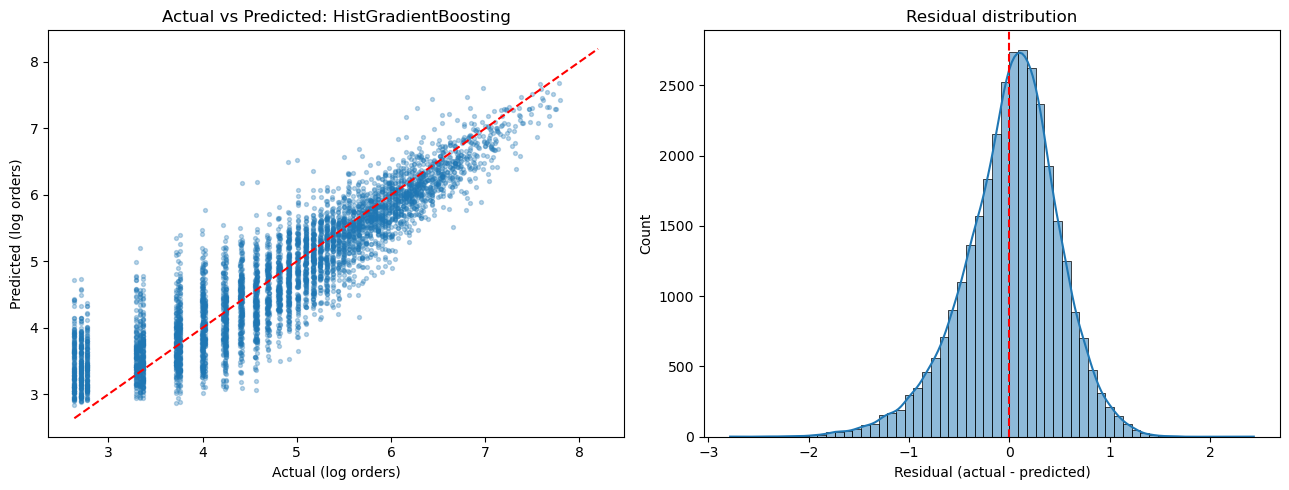

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

samp = np.random.RandomState(42).choice(len(y_test), size=min(5000, len(y_test)), replace=False)
ax[0].scatter(y_test.values[samp], best_pred[samp], alpha=0.3, s=8)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, 'r--')
ax[0].set_xlabel('Actual (log orders)'); ax[0].set_ylabel('Predicted (log orders)')
ax[0].set_title(f'Actual vs Predicted: {best_name}')

resid = y_test.values - best_pred
sns.histplot(resid, bins=60, kde=True, ax=ax[1])
ax[1].axvline(0, color='r', ls='--')
ax[1].set_xlabel('Residual (actual - predicted)')
ax[1].set_title('Residual distribution')
plt.tight_layout();
#plt.savefig('Charts/20_actual_vs_predicted_and_residuals.png', dpi=300, bbox_inches='tight')
plt.show()

## 11. Feature importance

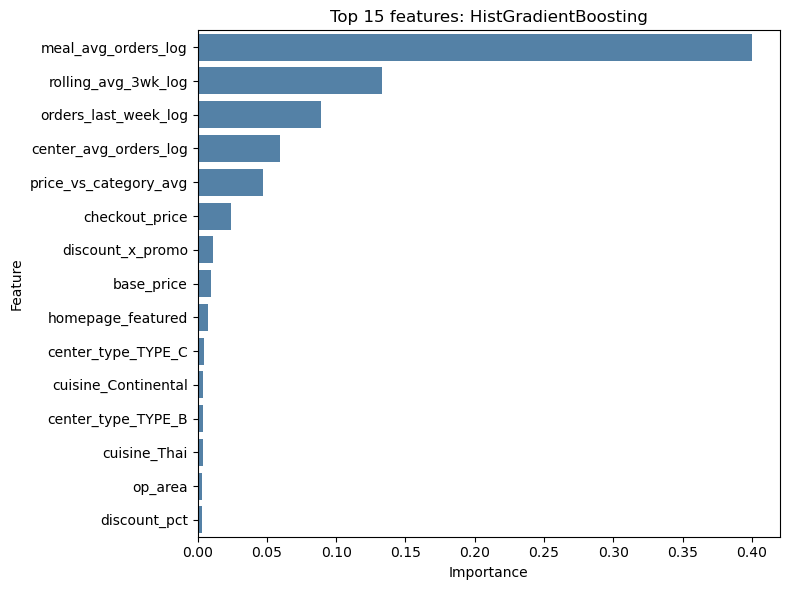

meal_avg_orders_log      0.400354
rolling_avg_3wk_log      0.132990
orders_last_week_log     0.088691
center_avg_orders_log    0.059299
price_vs_category_avg    0.047147
checkout_price           0.024269
discount_x_promo         0.010725
base_price               0.009296
homepage_featured        0.007750
center_type_TYPE_C       0.004856
cuisine_Continental      0.004090
center_type_TYPE_B       0.003900
cuisine_Thai             0.003781
op_area                  0.003268
discount_pct             0.002940
dtype: float64

In [17]:
model_map = {'Ridge': ridge, 'Random Forest': rf, GB_NAME: gb}
best_model = model_map[best_name]

if best_name == 'Ridge':
    imp = pd.Series(np.abs(best_model.named_steps['model'].coef_),
                    index=continuous_cols + binary_cols)
elif hasattr(best_model, 'feature_importances_'):
    imp = pd.Series(best_model.feature_importances_, index=X.columns)
else:
    from sklearn.inspection import permutation_importance
    pi = permutation_importance(best_model, X_test.sample(20000, random_state=42),
                                y_test.loc[X_test.sample(20000, random_state=42).index],
                                n_repeats=3, random_state=42, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=X.columns)

top = imp.sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color='steelblue')
plt.title(f'Top 15 features: {best_name}')
plt.xlabel('Importance'); plt.tight_layout(); plt.ylabel('Feature') ; 
#plt.savefig('Charts/21_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()
top

## 12. Error by week (does the model get worse further from training?)

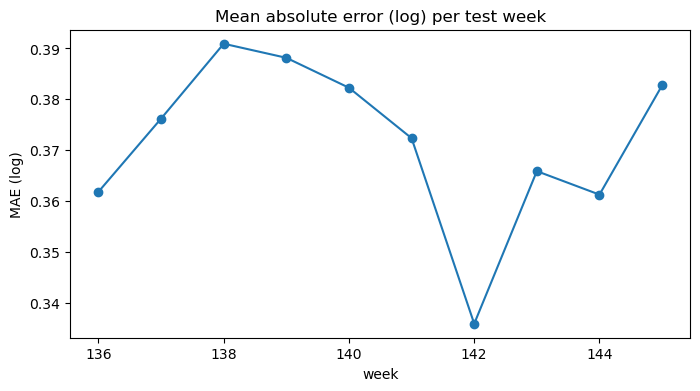

In [18]:
err = pd.DataFrame({'week': df.loc[test_mask, 'week'].values, 'abs_err': np.abs(resid)})
err.groupby('week')['abs_err'].mean().plot(marker='o', figsize=(8, 4),
    title='Mean absolute error (log) per test week')
plt.ylabel('MAE (log)');
#plt.savefig('Charts/22_error_by_week.png', dpi=300, bbox_inches='tight')
plt.show()

## 13. Optional experiments (good for the report)
**A. Does keeping `week` as a feature help?**

In [19]:
X_w = df.drop(columns=[c for c in ['num_orders', 'num_orders_log'] if c in df.columns])
gb_w = make_gb()
gb_w.fit(X_w[train_mask], y_train)
p = gb_w.predict(X_w[test_mask])
print(f'{GB_NAME} WITH week    : RMSLE = {np.sqrt(mean_squared_error(y_test, p)):.4f}')
print(f'{GB_NAME} WITHOUT week : RMSLE = {results_df.loc[GB_NAME, "RMSE (log) = RMSLE"]:.4f}')

HistGradientBoosting WITH week    : RMSLE = 0.5084
HistGradientBoosting WITHOUT week : RMSLE = 0.4823


**B. Leakage check:** recompute the two mean-encoded features from training weeks only and compare. (Week 3 limitation: they used the full dataset.)

This needs `center_id` and `meal_id`, which were dropped before saving. If you still have them in `preprocessed_food_demand.csv`, you can merge them back by row order. Skip this cell if they are not available.

In [ ]:
# Only run if you have center_id / meal_id available for df's rows.
# df['center_id'] = ...  ;  df['meal_id'] = ...
# tr = df[train_mask]
# for key, col in [('center_id', 'center_avg_orders_log'), ('meal_id', 'meal_avg_orders_log')]:
#     m = tr.groupby(key)[TARGET].mean()
#     df[col] = df[key].map(m).fillna(tr[TARGET].mean())
# ...then rebuild X, retrain the best model and compare RMSLE.

#### How does the model treat negative-discount rows?

In [20]:
t = X_test.copy()
t['y_true'] = y_test.values
t['y_pred'] = predictions[best_name]
t['abs_err'] = np.abs(t['y_true'] - t['y_pred'])
t['bias'] = t['y_true'] - t['y_pred']      # positive = model under-predicts

neg = t.groupby('has_negative_discount').agg(
    rows=('abs_err', 'size'), MAE_log=('abs_err', 'mean'), bias=('bias', 'mean'))
print(neg.round(4))

# Does dropping the flag, or clipping negative discounts to 0, change the score?
def rmsle_for(Xtr, Xte):
    m = make_gb(); m.fit(Xtr, y_train)
    return np.sqrt(mean_squared_error(y_test, m.predict(Xte)))

print('Baseline (flag kept)     :', round(rmsle_for(X_train, X_test), 4))
print('Flag removed             :', round(rmsle_for(X_train.drop(columns='has_negative_discount'),
                                                    X_test.drop(columns='has_negative_discount')), 4))
Xtr_c, Xte_c = X_train.copy(), X_test.copy()
Xtr_c['discount'] = Xtr_c['discount'].clip(lower=0)
Xte_c['discount'] = Xte_c['discount'].clip(lower=0)
print('Negative discount -> 0   :', round(rmsle_for(Xtr_c, Xte_c), 4))

                        rows  MAE_log    bias
has_negative_discount                        
0                      23822   0.3761  0.0123
1                       8999   0.3605  0.0188
Baseline (flag kept)     : 0.4823
Flag removed             : 0.4823
Negative discount -> 0   : 0.4822


#### How does the model treat outliers?

In [21]:
q1, q3 = y_train.quantile([0.25, 0.75])
low_f, high_f = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
t['group'] = np.where(t['y_true'] > high_f, 'high outlier',
              np.where(t['y_true'] < low_f, 'low outlier', 'normal'))
print(t.groupby('group').agg(rows=('abs_err', 'size'), MAE_log=('abs_err', 'mean'),
                             bias=('bias', 'mean')).round(4))
print('Share of train rows flagged as outliers:',
      round(((y_train > high_f) | (y_train < low_f)).mean() * 100, 2), '%')

# Alternative treatment: cap the training target at the 1st and 99th percentiles
lo, hi = y_train.quantile([0.01, 0.99])
m = make_gb(); m.fit(X_train, y_train.clip(lo, hi))
print('Outliers kept (log only):', round(np.sqrt(mean_squared_error(y_test, gb.predict(X_test))), 4))
print('Target capped 1%/99%    :', round(np.sqrt(mean_squared_error(y_test, m.predict(X_test))), 4))

         rows  MAE_log    bias
group                         
normal  32821   0.3718  0.0141
Share of train rows flagged as outliers: 0.08 %
Outliers kept (log only): 0.4823
Target capped 1%/99%    : 0.4822


#### Feature group ablation (why features were kept)

In [22]:
groups = {
 'price & promotion': [c for c in ['checkout_price','base_price','discount','discount_pct',
        'price_vs_category_avg','emailer_for_promotion','homepage_featured',
        'has_negative_discount','discount_x_promo'] if c in X.columns],
 'recent history':    [c for c in ['orders_last_week_log','rolling_avg_3wk_log'] if c in X.columns],
 'mean-encoded':      [c for c in ['center_avg_orders_log','meal_avg_orders_log'] if c in X.columns],
}
base = np.sqrt(mean_squared_error(y_test, gb.predict(X_test)))
rows = [{'Removed group': 'none (baseline)', 'RMSLE': round(base, 4), 'Change': 0.0}]
for name, cols in groups.items():
    s = rmsle_for(X_train.drop(columns=cols), X_test.drop(columns=cols))
    rows.append({'Removed group': name, 'RMSLE': round(s, 4), 'Change': round(s - base, 4)})
pd.DataFrame(rows)

,Removed group,RMSLE,Change
0,none (baseline),0.4823,0.0000
1,price & promotion,0.4980,0.0157
2,recent history,0.5159,0.0336
3,mean-encoded,0.4943,0.0120


#### Redundant features check

In [23]:
corr = X_train.corr().abs()
pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
             .stack().sort_values(ascending=False))
print(pairs[pairs > 0.85].head(10))
print(X_train.corrwith(y_train).abs().sort_values(ascending=False).head(10).round(3))

checkout_price         checkout_price_scaled    1.000000
op_area                op_area_scaled           1.000000
base_price             base_price_scaled        1.000000
checkout_price_scaled  base_price_scaled        0.952670
checkout_price         base_price_scaled        0.952670
base_price             checkout_price_scaled    0.952670
checkout_price         base_price               0.952670
orders_last_week_log   rolling_avg_3wk_log      0.926448
emailer_for_promotion  discount_x_promo         0.888598
discount               discount_pct             0.886365
dtype: float64
rolling_avg_3wk_log      0.836
orders_last_week_log     0.817
meal_avg_orders_log      0.732
checkout_price_scaled    0.392
checkout_price           0.392
base_price               0.330
base_price_scaled        0.330
category_Biryani         0.294
category_Rice Bowl       0.278
center_avg_orders_log    0.263
dtype: float64


In [24]:
dup_cols = [c for c in X.columns if c.endswith('_scaled')]
print(dup_cols)
print('Without scaled duplicates:', round(rmsle_for(X_train.drop(columns=dup_cols),
                                                    X_test.drop(columns=dup_cols)), 4))

['checkout_price_scaled', 'base_price_scaled', 'op_area_scaled']
Without scaled duplicates: 0.4823


## 14. Summary notes for the Word report
- Best model and its scores (table in section 9)
- Why a time-based split was used
- What the top features say about demand drivers
- Where the model struggles (residual plot and error-by-week)
- Limitations: mean-encoded features computed on full data, first-week lag values, single train/test split